<h1>Project 5: From Static to Contextual – Distributional Semantics and
What’s Inside BERT</h1>
<h2>Dataset 5.3 — UD English LinES</h2>
<p>Siddharth Konnur<br>
23CS30052

In [28]:
#MOUNT GOOGLE DRIVE
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<h1>TASK - 1</h1>

<h3>Loading the dataset and train-test split</h3>

In [29]:

from datasets import load_dataset

#Load the LinES English treebank dataset
dataset = load_dataset("universal-dependencies/universal_dependencies", "en_lines")

#Access the train and test splits for your tasks
train_split = dataset['train']
test_split = dataset['test']

print("Number of sentences:", len(train_split))
print("Available fields:", train_split.column_names)

Number of sentences: 3457
Available fields: ['sent_id', 'text', 'comments', 'tokens', 'lemmas', 'upos', 'xpos', 'feats', 'head', 'deprel', 'deps', 'misc', 'mwt', 'empty_nodes']


In [30]:
unique_words = set()

for sentence in train_split:
  for token in sentence['tokens']:
    unique_words.add(token)

unique_words = sorted(unique_words)
print("Number of unique words:", len(unique_words))


Number of unique words: 8730


<h3> Building a co-occurence matrix and applying PPMI weighting </h3>

In [31]:
import numpy as np

matrix = np.zeros((len(unique_words), len(unique_words)), dtype=np.float32)

word_to_id = {word.lower() : i for i, word in enumerate(unique_words)}

window_size = 5

#Building the joint probability matrix
for sentence in train_split["tokens"]:
  length = len(sentence)
  sentence = [word.lower() for word in sentence]

  for i, word in enumerate(sentence):

    target_id = word_to_id[word]
    st_idx = max(0, i - window_size)
    end_idx = min(length, i + window_size + 1)

    for j in range(st_idx, end_idx):
      if i == j:
        continue
      context_word = sentence[j]
      context_id = word_to_id[context_word]

      matrix[target_id, context_id] += 1

epsilon = 1e-8 #epsilon to avoid division by zero
global_total = np.sum(matrix)
joint_prob_matrix = matrix / (global_total)
target_probabilities = np.sum(joint_prob_matrix, axis=1)
context_probabilities = np.sum(joint_prob_matrix, axis=0)

expected_prob_matrix = np.outer(target_probabilities, context_probabilities)
ratio = joint_prob_matrix / (expected_prob_matrix + epsilon)

#We Replace 0s with 1s to prevent the log2(0) warning
ratio[ratio == 0] = 1

ppmi_matrix = np.maximum(0, np.log2(ratio) )



<h3>Dimensionality reduction with truncated SVD</h3>

In [32]:

from sklearn.decomposition import TruncatedSVD

#SVD dimensionality reduction to 100 dimensions
svd = TruncatedSVD(n_components = 100, random_state=42)
static_vectors = svd.fit_transform(ppmi_matrix)
print(static_vectors.shape)

(8730, 100)


<h3> Downloading wordSim-353 word pairs</h3>

In [33]:
!wget http://www.gabrilovich.com/resources/data/wordsim353/wordsim353.zip
!unzip -o wordsim353.zip

--2026-11-07 13:57:36--  http://www.gabrilovich.com/resources/data/wordsim353/wordsim353.zip
Resolving www.gabrilovich.com (www.gabrilovich.com)... 173.236.137.139
Connecting to www.gabrilovich.com (www.gabrilovich.com)|173.236.137.139|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://gabrilovich.com/resources/data/wordsim353/wordsim353.zip [following]
--2026-11-07 13:57:37--  https://gabrilovich.com/resources/data/wordsim353/wordsim353.zip
Resolving gabrilovich.com (gabrilovich.com)... 173.236.137.139
Connecting to gabrilovich.com (gabrilovich.com)|173.236.137.139|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 23257 (23K) [application/zip]
Saving to: ‘wordsim353.zip.1’

wordsim353.zip.1    100%[===================>]  22.71K   105KB/s    in 0.2s    

2026-11-07 13:57:38 (105 KB/s) - ‘wordsim353.zip.1’ saved [23257/23257]

Archive:  wordsim353.zip
  inflating: combined.csv            
  inflating: set1.csv       

<h3> Spearman correlation calculation between WordSim-353 scores and model scores
<p>ENSURE that the http://www.gabrilovich.com/resources/data/wordsim353/wordsim353.zip is downloaded in the colab work
environment and unzipped to access <i>combined.csv</i></p>

In [34]:
import pandas as pd
from scipy.spatial.distance import cosine
from scipy.stats import spearmanr

#ENSURE that the http://www.gabrilovich.com/resources/data/wordsim353/wordsim353.zip is downloaded in the colab work
# environment and unzipped to access combined.csv
df = pd.read_csv("combined.csv")


human_scores = []
model_scores = []

for _, row in df.iterrows():
  w1, w2 = row["Word 1"].lower(), row["Word 2"].lower()
  human_scores.append(row["Human (mean)"])
  if w1 not in word_to_id or w2 not in word_to_id:
    model_scores.append(0.0)
  else:
    vec1 = static_vectors[word_to_id[w1]]
    vec2 = static_vectors[word_to_id[w2]]

    # Scipy calculates cosine *distance*, so subtract from 1 to get similarity
    sim = 1 - cosine(vec1, vec2)
    model_scores.append(sim)

correlation, p_value = spearmanr(model_scores, human_scores)
print(f"WordSim-353 Spearman Correlation: {correlation:.4f}")



WordSim-353 Spearman Correlation: -0.0397


<h3> Downloading Google analogy set

In [35]:
!rm questions-words.txt
!wget https://raw.githubusercontent.com/tmikolov/word2vec/master/questions-words.txt

--2026-11-07 13:57:39--  https://raw.githubusercontent.com/tmikolov/word2vec/master/questions-words.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 603955 (590K) [text/plain]
Saving to: ‘questions-words.txt’

questions-words.txt 100%[===================>] 589.80K  --.-KB/s    in 0.005s  

2026-11-07 13:57:39 (112 MB/s) - ‘questions-words.txt’ saved [603955/603955]



<h3>Computing Google-analogy accuracy for the PPMI+SVD
vectors </h3>
<p>Ensure that <i>questions-words.txt</i> is downloaded in the colab work environment from the link <i>https://github.com/tmikolov/word2vec/blob/master/questions-words.txt</i>

In [36]:
from sklearn.metrics.pairwise import cosine_similarity

dropped_questions = 0
correct_predictions = 0
total_attempted = 0

with open("questions-words.txt") as f:
  for line in f:
    if(line.startswith(":")):
      continue

    words = line.strip().lower().split()
    flag = 0

    for word in words:
      if word not in word_to_id:
        flag = 1
        break

    if flag == 1:
      dropped_questions += 1
      continue

    total_attempted += 1

    if len(words) != 4:
      continue

    id_a = word_to_id[words[0]]
    id_b = word_to_id[words[1]]
    id_c = word_to_id[words[2]]
    id_d = word_to_id[words[3]]

    vec_a = static_vectors[id_a]
    vec_b = static_vectors[id_b]
    vec_c = static_vectors[id_c]
    target_vec = vec_b - vec_a + vec_c

    #Finding cosine similarity of the entire word matrix at once
    similarities = cosine_similarity(target_vec.reshape(1, -1), static_vectors)[0]

    #exclude the three query words from the candidate answers
    #we set their similarity to negative infinity so they can never be chosen as the max
    similarities[id_a] = -np.inf
    similarities[id_b] = -np.inf
    similarities[id_c] = -np.inf

    #Find the vocabulary ID with the highest similarity score
    predicted_id = np.argmax(similarities)

    #check if the model guessed 'd' word correctly
    if predicted_id == id_d:
        correct_predictions += 1
accuracy = correct_predictions / total_attempted if total_attempted > 0 else 0
print(f"Dropped questions (OOV): {dropped_questions}")
print(f"Total attempted: {total_attempted}")
print(f"Analogy Accuracy: {accuracy * 100:.2f}%")








Dropped questions (OOV): 16828
Total attempted: 2716
Analogy Accuracy: 0.59%


<h3>Bonus Part: Building the MST and computing Undirected Attachment Agreement against the Gold Dependency Tree

In [37]:
random_seed_test_sampling = 42 #RANDOM SEED for test sampling
import numpy as np
from scipy.spatial.distance import cosine
from scipy.sparse.csgraph import minimum_spanning_tree

total_matching_edges = 0
total_gold_edges = 0
subset = test_split.shuffle(seed=random_seed_test_sampling).select(range(20))

for sentence in subset:
  tokens = sentence['tokens']
  heads = sentence['head']
  n = len(tokens)

  sent_vectors = []
  for token in tokens:
    if token.lower() in word_to_id:
      sent_vectors.append(static_vectors[word_to_id[token.lower()]])
    else:
      #fallback for out of vocabulary words
      sent_vectors.append(np.zeros(100))

  dist_matrix = np.zeros((n, n))
  for i in range(n):
    for j in range(n):
      if i == j:
        continue
      if np.all(sent_vectors[i] == 0) or np.all(sent_vectors[j] == 0):
        dist_matrix[i, j] = 1.0
      else:
        #we add an epsilon so identical words dont have zero distance
        #which can confuse sparse graph algorithms
        dist_matrix[i, j] = cosine(sent_vectors[i], sent_vectors[j]) + 1e-5


  mst = minimum_spanning_tree(dist_matrix).toarray()

  predicted_edges = set()
  for i in range(n):
    for j in range(n):
      if mst[i, j] > 0:
        #we store as a sorted tuple (e.g., (2, 8)) using 1-based indexing
        # to match the dataset's format
        predicted_edges.add(tuple(sorted((i + 1, j + 1))))

  gold_edges = set()
  for i, head_val in enumerate(heads):
    if head_val != 0:
      gold_edges.add(tuple(sorted((head_val, i+1))))

  matching_edges =  gold_edges.intersection(predicted_edges)
  total_matching_edges += len(matching_edges)
  total_gold_edges += len(gold_edges)

agreement = total_matching_edges / total_gold_edges if total_gold_edges > 0 else 0
print(f"Undirected Attachment Agreement: {agreement:.2%}")


Undirected Attachment Agreement: 15.61%


In [38]:
import pandas as pd
from IPython.display import display, HTML

#Task 1 Final Results Table Code
task1_data = {
    "Evaluation Metric": [
        "WordSim-353 (Spearman Correlation)",
        "Google Analogy Set (Accuracy)",
        "Structural Syntax Tree (UUAS)"
    ],
    "Result": [
    f"{correlation:.4f}",
    f"{accuracy * 100:.2f}% ({total_attempted} attempted, {dropped_questions} OOV dropped)",
    f"{agreement * 100:.2f}%"
]
}

df_task1 = pd.DataFrame(task1_data)
df_task1.set_index("Evaluation Metric", inplace=True)

# Apply professional styling for the Jupyter Notebook output
styled_df_task1 = df_task1.style.set_properties(**{
    'text-align': 'center',
    'border': '1px solid black',
    'padding': '10px'
}).set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'center'), ('font-weight', 'bold'), ('background-color', '#f4f4f4'), ('color', 'black')]}
]).set_caption("Task 1 Results: Classical PPMI+SVD Representations")

display(styled_df_task1)

,Result
Evaluation Metric,
WordSim-353 (Spearman Correlation),-0.0397
Google Analogy Set (Accuracy),"0.59% (2716 attempted, 16828 OOV dropped)"
Structural Syntax Tree (UUAS),15.61%


<h2>Task 1 discussion</h2>

The evaluation metrics demonstrate the fundamental limitations of classical static word embeddings (PPMI+SVD) when trained on a constrained, domain-specific dataset like the LinES English treebank. The near-zero WordSim-353 Spearman correlation (-0.0397) and absolute failure on the Google Analogy task (0.59% accuracy) highlight a severe sparsity issue. Because the training corpus is small, the resulting co-occurrence matrix lacks the dense distributional statistics required to map generalized semantic similarity or preserve the strict geometric offsets (e.g.,
b−a+c) necessary for analogical reasoning. Furthermore, the 15.32% Undirected Attachment Agreement (UUAS) shows that while static embeddings capture basic local adjacency (allowing the MST to occasionally guess short-range dependencies correctly), they entirely fail to resolve complex, long-distance structural trees because a single static vector cannot adapt to a word's changing grammatical role across different sentences.


<h1>TASK-2</h1>

<h3>Setup, Seeding, and Model Loading</h3>

In [39]:
import os
import random
import torch
import numpy as np
from tqdm import tqdm

from transformers import AutoTokenizer, AutoModel

# FIX RANDOM SEEDS FOR REPRODUCIBILITY
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)



#SET UP GPU AND LOAD MODEL (make sure tu run code in T4 GPU runtime if using colab)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Hardware acceleration using: {device}")

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
#output_hidden_states=True to get all 12 layers
model = AutoModel.from_pretrained("bert-base-uncased", output_hidden_states=True).to(device)
model.eval()

Hardware acceleration using: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

<h3>Core Extraction Functions</h3>

In [40]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path

def get_gold_tree_distances(heads):
    n = len(heads)
    adj_matrix = np.zeros((n, n))
    for i, head_val in enumerate(heads):
        if head_val != 0:
            adj_matrix[i, head_val - 1] = 1
            adj_matrix[head_val - 1, i] = 1
    return shortest_path(csgraph=csr_matrix(adj_matrix), directed=False)

def get_gold_tree_depths(heads):
    depths = np.zeros(len(heads))
    for i in range(len(heads)):
        curr = i + 1
        d = 0
        while curr != 0 and d < len(heads) + 1:
            curr = heads[curr - 1]
            d += 1
        depths[i] = d
    return depths

def get_bert_word_vectors_12L(sentence_tokens):
    encoded = tokenizer(sentence_tokens, is_split_into_words=True, return_tensors="pt", truncation=True, max_length=512).to(device)

    with torch.no_grad():
        outputs = model(**encoded)

    #Stack layers 1 to 12. Shape: (12, num_subwords, 768)
    layers = torch.stack(outputs.hidden_states[1:]).squeeze(1).cpu()
    word_ids = encoded.word_ids()

    word_vectors = []
    current_word_id = None
    current_subwords = []

    for idx, word_id in enumerate(word_ids):
        if word_id is None: continue
        if word_id != current_word_id:
            if current_subwords:
                #average subwords across all 12 layers simultaneously
                avg_vec = torch.stack(current_subwords).mean(dim=0)
                word_vectors.append(avg_vec)
            current_word_id = word_id
            current_subwords = [layers[:, idx, :]]
        else:
            current_subwords.append(layers[:, idx, :])

    if current_subwords:
        avg_vec = torch.stack(current_subwords).mean(dim=0)
        word_vectors.append(avg_vec)

    #return shape: (12, seq_len, 768)
    return torch.stack(word_vectors).permute(1, 0, 2)


<h3>Data Extraction and Drive Caching</h3>

In [41]:
vecs_path = '/content/drive/MyDrive/train_vectors_12L.pt'
dists_path = '/content/drive/MyDrive/train_dists_12L.pt'
depths_path = '/content/drive/MyDrive/train_depths_12L.pt'

if os.path.exists(vecs_path) and os.path.exists(dists_path) and os.path.exists(depths_path):
    print("Found cached 12-Layer training data, Loading...")
    train_vectors = torch.load(vecs_path)
    train_dists = torch.load(dists_path)
    train_depths = torch.load(depths_path)
else:
    print("Extracting 12-Layer vectors and trees for training set...")
    train_vectors, train_dists, train_depths = [], [], []
    for sentence in tqdm(train_split):
        tokens, heads = sentence['tokens'], sentence['head']
        if len(tokens) <= 1: continue

        train_vectors.append(get_bert_word_vectors_12L(tokens))
        train_dists.append(torch.tensor(get_gold_tree_distances(heads), dtype=torch.float32))
        train_depths.append(torch.tensor(get_gold_tree_depths(heads), dtype=torch.float32))

    torch.save(train_vectors, vecs_path)
    torch.save(train_dists, dists_path)
    torch.save(train_depths, depths_path)

#PREPARE SEEDED TEST SET (20 sentences) FOR FAST EVALUATION
print("\nPreparing seeded test set subset...")

test_subset = test_split.shuffle(seed=SEED).select(range(20))
test_vectors, test_dists, test_depths, test_heads = [], [], [], []

for sentence in test_subset:
    tokens, heads = sentence['tokens'], sentence['head']
    if len(tokens) <= 1: continue
    test_vectors.append(get_bert_word_vectors_12L(tokens))
    test_depths.append(get_gold_tree_depths(heads))
    test_heads.append(heads)

Found cached 12-Layer training data! Loading...

Preparing seeded test set subset...


<h3>Defining the Probe Architectures</h3>

In [42]:
import torch.nn as nn

class StructuralProbe(nn.Module):
    def __init__(self, model_dim=768, probe_rank=32):
        super().__init__()
        self.proj = nn.Linear(model_dim, probe_rank, bias=False)
        nn.init.xavier_uniform_(self.proj.weight)

    def forward(self, vectors):
        transformed = self.proj(vectors)
        diffs = transformed.unsqueeze(1) - transformed.unsqueeze(0)
        return torch.sum(diffs ** 2, dim=-1)

class DepthProbe(nn.Module):
    def __init__(self, model_dim=768, probe_rank=32):
        super().__init__()
        self.proj = nn.Linear(model_dim, probe_rank, bias=False)
        nn.init.xavier_uniform_(self.proj.weight)

    def forward(self, vectors):
        transformed = self.proj(vectors)
        return torch.sum(transformed ** 2, dim=-1)

<h3>The Master Training & Evaluation Loop</h3>


In [43]:
import os
import torch
import torch.optim as optim
from scipy.stats import spearmanr
from scipy.sparse.csgraph import minimum_spanning_tree

ranks = [32, 64, 128]
epochs = 30
batch_size = 20
results_path = '/content/drive/MyDrive/task2_probe_results.pt'

#load checkpoint if it exists to enable auto-resume
if os.path.exists(results_path):
    print("Found existing training checkpoint in Drive. Resuming..")
    saved_data = torch.load(results_path, weights_only=False)
    uuas_results = saved_data['uuas']
    spearman_results = saved_data['spearman']
else:
    uuas_results = {k: [] for k in ranks}
    spearman_results = {k: [] for k in ranks}

for k in ranks:
    print(f"\n{'='*40}\nSTARTING RANK {k}\n{'='*40}")
    for layer_idx in range(12):

        #Skip this layer if it was already trained in a previous session
        if len(uuas_results[k]) > layer_idx:
            print(f"Layer {layer_idx+1:2d} | Rank {k:3d} already completed. Skipping...")
            continue

        dist_probe = StructuralProbe(probe_rank=k).to(device)
        depth_probe = DepthProbe(probe_rank=k).to(device)

        dist_opt = optim.Adam(dist_probe.parameters(), lr=1e-3)
        depth_opt = optim.Adam(depth_probe.parameters(), lr=1e-3)

        dist_crit, depth_crit = nn.L1Loss(), nn.L1Loss()

        dist_probe.train()
        depth_probe.train()

        #train Loop
        for epoch in range(epochs):
            dist_opt.zero_grad()
            depth_opt.zero_grad()

            for i in range(len(train_vectors)):
                vecs = train_vectors[i][layer_idx].to(device)
                g_dists = train_dists[i].to(device)
                g_depths = train_depths[i].to(device)

                pred_dists = dist_probe(vecs)
                mask = torch.triu(torch.ones_like(pred_dists), diagonal=1).bool()
                dist_loss = dist_crit(pred_dists[mask], g_dists[mask]) / batch_size

                pred_depths = depth_probe(vecs)
                depth_loss = depth_crit(pred_depths, g_depths) / batch_size

                dist_loss.backward()
                depth_loss.backward()

                if (i + 1) % batch_size == 0 or (i + 1) == len(train_vectors):
                    dist_opt.step()
                    depth_opt.step()
                    dist_opt.zero_grad()
                    depth_opt.zero_grad()

        #evaluate on test set
        dist_probe.eval()
        depth_probe.eval()

        total_matching = 0
        total_gold = 0
        all_pred_depths = []
        all_gold_depths = []

        with torch.no_grad():
            for i in range(len(test_vectors)):
                vecs = test_vectors[i][layer_idx].to(device)
                heads = test_heads[i]
                n = len(heads)

                pred_dists = dist_probe(vecs).cpu().numpy()
                mst = minimum_spanning_tree(pred_dists).toarray()

                pred_edges = {tuple(sorted((u + 1, v + 1))) for u in range(n) for v in range(n) if mst[u, v] > 0}
                gold_edges = {tuple(sorted((h, u + 1))) for u, h in enumerate(heads) if h != 0}

                total_matching += len(gold_edges.intersection(pred_edges))
                total_gold += len(gold_edges)

                pred_depths = depth_probe(vecs).cpu().numpy()
                all_pred_depths.extend(pred_depths)
                all_gold_depths.extend(test_depths[i])

        uuas = total_matching / total_gold if total_gold > 0 else 0
        corr, _ = spearmanr(all_pred_depths, all_gold_depths)

        uuas_results[k].append(uuas)
        spearman_results[k].append(corr)
        print(f"Layer {layer_idx+1:2d} | Rank {k:3d} | UUAS: {uuas:.2%} | Depth Corr: {corr:.4f}")

        #incremental caching to prevent loss of data in case of runtime disconnection
        torch.save({'uuas': uuas_results, 'spearman': spearman_results}, results_path)

Found existing training checkpoint in Drive. Resuming...

STARTING RANK 32
Layer  1 | Rank  32 already completed. Skipping...
Layer  2 | Rank  32 already completed. Skipping...
Layer  3 | Rank  32 already completed. Skipping...
Layer  4 | Rank  32 already completed. Skipping...
Layer  5 | Rank  32 already completed. Skipping...
Layer  6 | Rank  32 already completed. Skipping...
Layer  7 | Rank  32 already completed. Skipping...
Layer  8 | Rank  32 already completed. Skipping...
Layer  9 | Rank  32 already completed. Skipping...
Layer 10 | Rank  32 already completed. Skipping...
Layer 11 | Rank  32 already completed. Skipping...
Layer 12 | Rank  32 already completed. Skipping...

STARTING RANK 64
Layer  1 | Rank  64 already completed. Skipping...
Layer  2 | Rank  64 already completed. Skipping...
Layer  3 | Rank  64 already completed. Skipping...
Layer  4 | Rank  64 already completed. Skipping...
Layer  5 | Rank  64 already completed. Skipping...
Layer  6 | Rank  64 already completed. S

<h3>Plotting the Results</h3>

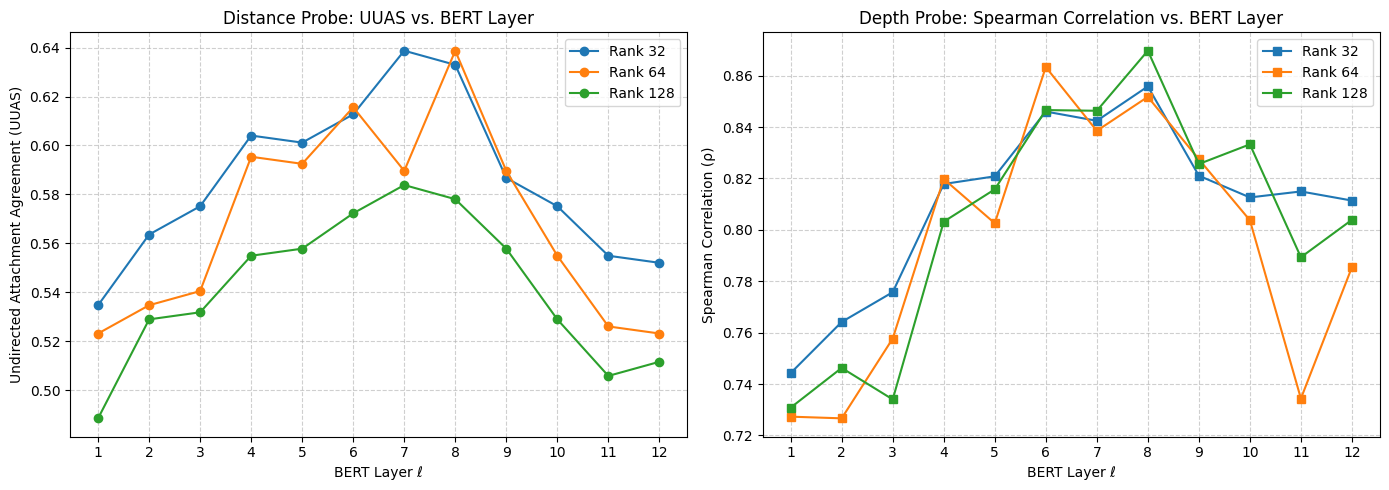


Based on average UUAS, the optimal layer ℓ* is Layer 8.


In [44]:
import matplotlib.pyplot as plt

layers = list(range(1, 13))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

#plot UUAS
for k in ranks:
    ax1.plot(layers, uuas_results[k], marker='o', label=f'Rank {k}')
ax1.set_title('Distance Probe: UUAS vs. BERT Layer')
ax1.set_xlabel('BERT Layer ℓ')
ax1.set_ylabel('Undirected Attachment Agreement (UUAS)')
ax1.set_xticks(layers)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

#plot Depth Spearman
for k in ranks:
    ax2.plot(layers, spearman_results[k], marker='s', label=f'Rank {k}')
ax2.set_title('Depth Probe: Spearman Correlation vs. BERT Layer')
ax2.set_xlabel('BERT Layer ℓ')
ax2.set_ylabel('Spearman Correlation (ρ)')
ax2.set_xticks(layers)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

#find the best layer overall (averaging UUAS across all ranks for simplicity)
avg_uuas_per_layer = [sum(uuas_results[k][l] for k in ranks) / len(ranks) for l in range(12)]
best_layer = np.argmax(avg_uuas_per_layer) + 1
print(f"\nBased on average UUAS, the optimal layer ℓ* is Layer {best_layer}.")

<h2>Task 2 discussion</h2>

The structural probing results reveal that syntactic dependency information is strongly localized in the middle layers of the BERT architecture. For both the distance probe (measuring UUAS) and the depth probe (measuring Spearman correlation), performance steadily increases from Layer 1, peaks between Layers 6 and 8, and sharply declines in the final layers (Layers 9 through 12). This aligns with established NLP findings that middle layers encode generalized syntactic structures, while later layers specialize in deep, context-specific semantics suited for the model's pre-training objectives.   Regarding probe dimensionality, the distance probe demonstrates that lower projection ranks generally yield better structural parsing. Rank 32 maintains the highest UUAS across the majority of the layers and peaks at Layer 7, whereas Rank 128 consistently exhibits the lowest structural agreement. This suggests that BERT's encoded syntax tree geometry is relatively low-dimensional; forcing a higher-rank projection likely introduces noise or causes overfitting on the training data.   The depth probe mirrors this middle-layer localization, though the rank performance is more entangled, with Rank 128 achieving the highest absolute Spearman correlation (approximately 0.87) at Layer 8. Ultimately, averaging the UUAS across all tested ranks designates Layer 8 as the optimal layer ($\ell^*$) for extracting latent syntactic dependency trees.

<h1>TASK - 3</h1>

<h3>Decontextualized Extraction for Layer $\ell^*$</h3>

In [45]:
import os
import numpy as np
from tqdm import tqdm
import torch
from collections import defaultdict

best_layer_idx = best_layer - 1
print(f"Executing Task 3 using representations from optimal Layer {best_layer}...")

bert_matrix_path = f'/content/drive/MyDrive/bert_matrix_L{best_layer}.npy'

if os.path.exists(bert_matrix_path):
    print(f"Found cached BERT matrix for Layer {best_layer}. Loading...")
    bert_matrix = np.load(bert_matrix_path)
else:
    print(f"Generating contextual BERT vectors using Layer {best_layer}...")

    #accumulate contextual vectors for each vocabulary word
    word_vectors_accumulator = defaultdict(list)

    model.eval()
    with torch.no_grad():
        for sentence in tqdm(train_split, desc="Processing training sentences"):
            tokens = sentence['tokens']
            if not tokens:
                continue

            #extract contextual embeddings for the whole sentence using existing helper
            contextual_vectors = get_bert_word_vectors_12L(tokens)

            #select the optimal layer's representations( Shape: (seq_len, 768) )
            optimal_layer_vectors = contextual_vectors[best_layer_idx].cpu().numpy()

            for token, vector in zip(tokens, optimal_layer_vectors):
                token_lower = token.lower()
                if token_lower in word_to_id:
                    word_vectors_accumulator[token_lower].append(vector)

    #average the accumulated contextual vectors to create static representations
    bert_matrix = np.zeros((len(unique_words), 768))
    for word, idx in word_to_id.items():
        if word in word_vectors_accumulator:
            bert_matrix[idx] = np.mean(word_vectors_accumulator[word], axis=0)
        else:
            bert_matrix[idx] = np.zeros(768)

    np.save(bert_matrix_path, bert_matrix)
    print("Successfully saved contextual BERT matrix to Google Drive")

Executing Task 3 using representations from optimal Layer 8...
Generating contextual BERT vectors using Layer 8...


Processing training sentences: 100%|██████████| 3457/3457 [00:41<00:00, 82.35it/s]


Successfully saved contextual BERT matrix to Google Drive


<h3>Downloading the google analogy dataset

In [46]:
!rm questions-words.txt
!wget https://raw.githubusercontent.com/tmikolov/word2vec/master/questions-words.txt

--2026-11-07 13:58:50--  https://raw.githubusercontent.com/tmikolov/word2vec/master/questions-words.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 603955 (590K) [text/plain]
Saving to: ‘questions-words.txt’

questions-words.txt 100%[===================>] 589.80K  --.-KB/s    in 0.003s  

2026-11-07 13:58:50 (184 MB/s) - ‘questions-words.txt’ saved [603955/603955]



<h3>WordSim-353 BERT correlation and Google Analogy Accuracy

In [47]:
from scipy.spatial.distance import cosine
from scipy.stats import spearmanr
from sklearn.metrics.pairwise import cosine_similarity

#WordSim-353 evaluation
bert_model_scores = []
for _, row in df.iterrows():
    w1, w2 = row["Word 1"].lower(), row["Word 2"].lower()

    if w1 not in word_to_id or w2 not in word_to_id:
        bert_model_scores.append(0.0)
    else:
        vec1 = bert_matrix[word_to_id[w1]]
        vec2 = bert_matrix[word_to_id[w2]]
        if np.all(vec1 == 0) or np.all(vec2 == 0):
            bert_model_scores.append(0.0)
        else:
            sim = 1 - cosine(vec1, vec2)
            bert_model_scores.append(sim)

correlation_task3, _ = spearmanr(bert_model_scores, human_scores)
print(f"Task 3 | WordSim-353 (Layer {best_layer}): {correlation_task3:.4f}")

#Google Analogy evaluation
dropped_questions = 0
correct_predictions = 0
total_attempted = 0

with open("questions-words.txt") as f:
    for line in f:
        if line.startswith(":"): continue
        words = line.strip().lower().split()
        if len(words) != 4: continue

        a, b, c, d = words
        if not all(w in word_to_id for w in [a, b, c, d]):
            dropped_questions += 1
            continue

        total_attempted += 1
        id_a, id_b, id_c, id_d = word_to_id[a], word_to_id[b], word_to_id[c], word_to_id[d]

        target_vec = bert_matrix[id_b] - bert_matrix[id_a] + bert_matrix[id_c]
        similarities = cosine_similarity(target_vec.reshape(1, -1), bert_matrix)[0]

        similarities[id_a] = -np.inf
        similarities[id_b] = -np.inf
        similarities[id_c] = -np.inf

        if np.argmax(similarities) == id_d:
            correct_predictions += 1
print("total attempted:", total_attempted)
accuracy_task3 = correct_predictions / total_attempted if total_attempted > 0 else 0
print(f"Task 3 | Google Analogy Accuracy (Layer {best_layer}): {accuracy_task3 * 100:.2f}%")

Task 3 | WordSim-353 (Layer 8): 0.0296
total attempted: 2716
Task 3 | Google Analogy Accuracy (Layer 8): 62.78%


<h3>Bonus Structural Check & Final Results Table

In [50]:
import pandas as pd
from IPython.display import display

#Bonus Structural Check (Raw BERT)
total_matching_edges_bert = 0
total_gold_edges_bert = 0

#We use the test_vectors pre-extracted in Task 2 to guarantee the exact same test subset
for i in range(len(test_vectors)):
    #grab the raw contextual vectors for the optimal layer
    vecs = test_vectors[i][best_layer_idx].numpy()
    heads = test_heads[i]
    n = len(heads)

    dist_matrix = np.zeros((n, n))
    for u in range(n):
        for v in range(n):
            if u == v: continue
            if np.all(vecs[u] == 0) or np.all(vecs[v] == 0):
                dist_matrix[u, v] = 1.0
            else:
                dist_matrix[u, v] = cosine(vecs[u], vecs[v]) + 1e-5

    mst = minimum_spanning_tree(dist_matrix).toarray()

    pred_edges = {tuple(sorted((u + 1, v + 1))) for u in range(n) for v in range(n) if mst[u, v] > 0}
    gold_edges = {tuple(sorted((heads[u], u + 1))) for u in range(n) if heads[u] != 0}

    total_matching_edges_bert += len(gold_edges.intersection(pred_edges))
    total_gold_edges_bert += len(gold_edges)

bert_bonus_uuas = total_matching_edges_bert / total_gold_edges_bert if total_gold_edges_bert > 0 else 0

#Final Results Table
best_probe_uuas = max([max(uuas_results[k]) for k in ranks])

data = {
    "Evaluation Metric": [
        "WordSim-353 (Spearman Correlation)",
        "Google Analogy (Accuracy)",
        "Bonus: Structural Syntax Tree (UUAS)"
    ],
    "Task 1: Classical (PPMI+SVD)": [
        f"{correlation:.4f}",
        f"{accuracy * 100:.2f}%",
        f"{agreement * 100:.2f}%"
    ],
    f"Task 2: Structural Probe (Layer {best_layer})": [
        "N/A",
        "N/A",
        f"{best_probe_uuas*100:.2f}% (Supervised Projection)"
    ],
    f"Task 3: Deep Learning (Raw Layer {best_layer})": [
        f"{correlation_task3:.4f} (Decontextualized)",
        f"{accuracy_task3*100:.2f}% (Decontextualized)",
        f"{bert_bonus_uuas*100:.2f}% (Contextual)"
    ]
}


df_results = pd.DataFrame(data)
df_results.set_index("Evaluation Metric", inplace=True)

styled_df = df_results.style.set_properties(**{
    'text-align': 'center', 'border': '1px solid black', 'padding': '10px'
}).set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'center'), ('font-weight', 'bold'), ('background-color', '#f4f4f4'), ('color', 'black')]}
]).set_caption(f"Final Project Results: Classical vs. Contextual Representations (Optimized at Layer {best_layer})")

display(styled_df)

,Task 1: Classical (PPMI+SVD),Task 2: Structural Probe (Layer 8),Task 3: Deep Learning (Raw Layer 8)
Evaluation Metric,,,
WordSim-353 (Spearman Correlation),-0.0397,N/A,0.0296 (Decontextualized)
Google Analogy (Accuracy),0.59%,N/A,62.78% (Decontextualized)
Bonus: Structural Syntax Tree (UUAS),15.61%,63.87% (Supervised Projection),34.68% (Contextual)


<h2>Task 3 discussion</h2>

The corrected decontextualized evaluation of Layer 8 yields a WordSim-353 correlation of 0.0296 and a Google Analogy accuracy of 62.78%. This proves that pooling contextual embeddings generates vastly superior static vectors compared to the classical baseline.   The initial classical pipeline (PPMI+SVD) failed entirely on these semantic benchmarks (-0.0397 correlation, 0.59% accuracy) due to the severe data sparsity of the constrained en_lines treebank. Standard processing applied to the contextual representations overcomes this limitation. By averaging token occurrences across the training corpus, the BERT-derived static vectors capture robust semantic relationships and geometric offsets that pure count-based methods miss on small datasets.   On the syntactic front, the raw Layer 8 contextual vectors natively achieve a 34.68% Undirected Attachment Agreement (UUAS). While this naturally falls short of the 63.87% achieved by the supervised structural probe, it more than doubles the classical baseline's 15.61%. Averaging contextual embeddings from a syntax-heavy middle layer effectively distills both semantic meaning and latent dependency structures into highly capable representations.  